<a href="https://colab.research.google.com/github/NetoGC/titanic-disaster-ml/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Para acessar arquivos no seu Google Drive, você precisa montá-lo primeiro. Isso permite que o Colab veja seus arquivos armazenados na nuvem.

In [225]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Depois de montar o Drive, é comum que os arquivos de notebooks estejam na pasta `My Drive/Colab Notebooks`. Você pode listar o conteúdo dessa pasta para ver os arquivos disponíveis.

In [226]:
import os
import pandas as pd
from IPython.display import display_html
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

path_to_data = '/content/drive/MyDrive/titanicKaggle'

# Verifique se o diretório existe, e crie-o se não existir
if not os.path.exists(path_to_data):
    print(f"Diretório '{path_to_data}' não encontrado. Tentando criá-lo.")
    os.makedirs(path_to_data, exist_ok=True) # exist_ok=True evita erro se o diretório já existe
    print(f"Diretório '{path_to_data}' criado (se não existia). Por favor, certifique-se de que seus arquivos estão aqui no Google Drive.")
else:
    print(f"Diretório '{path_to_data}' encontrado.")

os.chdir(path_to_data)

print(os.listdir())

Diretório '/content/drive/MyDrive/titanicKaggle' encontrado.
['train.csv', 'test.csv', 'gender_submission.csv', 'resultado.csv', 'resultado2.csv', 'resultado1.csv']


Agora que você sabe o nome do seu arquivo CSV (substitua `seu_arquivo.csv` pelo nome correto na célula abaixo), você pode carregá-lo usando a biblioteca `pandas`.

In [227]:

try:
    df_train = pd.read_csv('train.csv') # Alterado para 'train.csv'
    print("Arquivo CSV carregado com sucesso!")
except FileNotFoundError:
    print("Erro: O arquivo 'train.csv' não foi encontrado. Verifique o nome e o caminho.")
except Exception as e:
    print(f"Ocorreu um erro ao carregar o arquivo: {e}")

Arquivo CSV carregado com sucesso!


In [228]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [229]:
df_train.isnull().sum().sort_values(ascending=False)

,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


In [230]:
try:
    df_test = pd.read_csv('test.csv')
    print("Arquivo CSV carregado com sucesso!")
except FileNotFoundError:
    print("Erro: O arquivo 'test.csv' não foi encontrado. Verifique o nome e o caminho.")
except Exception as e:
    print(f"Ocorreu um erro ao carregar o arquivo: {e}")
df_test.head()

Arquivo CSV carregado com sucesso!


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [231]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [232]:
# Verificando Valores Nulos na base de treino e teste
df_train_null = df_train.isnull().sum().sort_values(ascending=False).to_frame(name='Nulos (Treino)')
df_test_null = df_test.isnull().sum().sort_values(ascending=False).to_frame(name='Nulos (Teste)')

print("=== Valores Nulos: Base de Treino ===")
display(df_train_null)

print("\n=== Valores Nulos: Base de Teste ===")
display(df_test_null)

=== Valores Nulos: Base de Treino ===


,Nulos (Treino)
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0



=== Valores Nulos: Base de Teste ===


,Nulos (Teste)
Cabin,327
Age,86
Fare,1
Name,0
Pclass,0
PassengerId,0
Sex,0
Parch,0
SibSp,0
Ticket,0


In [233]:
# Verificando a cardinalidade dos dados
df_train.nunique().sort_values(ascending=False)

,0
PassengerId,891
Name,891
Ticket,681
Fare,248
Cabin,147
Age,88
SibSp,7
Parch,7
Embarked,3
Pclass,3


In [234]:
# TRATAMENTO DE DADOS

In [235]:

df_train = df_train.drop(['Name', 'Ticket', 'Cabin'], axis=1)
df_test = df_test.drop(['Name', 'Ticket', 'Cabin'], axis=1)

print('TRAIN')
print(df_train.head())
print('\n TEST')
print(df_test.head())

TRAIN
   PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0            1         0       3    male  22.0      1      0   7.2500        S
1            2         1       1  female  38.0      1      0  71.2833        C
2            3         1       3  female  26.0      0      0   7.9250        S
3            4         1       1  female  35.0      1      0  53.1000        S
4            5         0       3    male  35.0      0      0   8.0500        S

 TEST
   PassengerId  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0          892       3    male  34.5      0      0   7.8292        Q
1          893       3  female  47.0      1      0   7.0000        S
2          894       2    male  62.0      0      0   9.6875        Q
3          895       3    male  27.0      0      0   8.6625        S
4          896       3  female  22.0      1      1  12.2875        S


In [236]:
df_train.loc[df_train.Age.isnull(), 'Age'] = np.round((df_train.Age.mean() * 2) / 2 )
df_test.loc[df_test.Age.isnull(), 'Age'] = np.round((df_test.Age.mean() * 2) / 2 )

print('TRAIN')
print(df_train.Age.isnull().sum())
print('\n TEST')
print(df_test.Age.isnull().sum())


TRAIN
0

 TEST
0


In [237]:
print('TRAIN')
print(df_train['Embarked'].value_counts())
print('\n TEST')
print(df_test['Embarked'].value_counts())

TRAIN
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

 TEST
Embarked
S    270
C    102
Q     46
Name: count, dtype: int64


In [238]:
df_train.loc[df_train.Embarked.isnull(), 'Embarked'] = 'S'
df_test.loc[df_test.Embarked.isnull(), 'Embarked'] = 'S'

print('TRAIN')
print(df_train.Embarked.isnull().sum())
print('\n TEST')
print(df_test.Embarked.isnull().sum())

TRAIN
0

 TEST
0


In [239]:
df_train.loc[df_train.Fare.isnull(), 'Fare'] = df_train.Fare.mean()
df_test.loc[df_test.Fare.isnull(), 'Fare'] = df_test.Fare.mean()

print('TRAIN')
print(df_train.isnull().sum().sort_values(ascending=False))
print('\n TEST')
print(df_test.isnull().sum().sort_values(ascending=False))


TRAIN
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64

 TEST
PassengerId    0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64


In [240]:
df_train_num = df_train.select_dtypes(include=['int64', 'float64'])
df_test_num = df_test.select_dtypes(include=['int64', 'float64'])


In [241]:
# SEPARAÇÃO DA BASE DE TREINO EM "X" E "Y", E EM TREINO E VALIDAÇÃO

In [242]:
X = df_train_num.drop(['PassengerId', 'Survived'], axis=1) # remoção da coluna 'PassengerId' para evitar Overfitting e melhorar a Generalização
y = df_train_num.Survived

In [243]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [244]:
# UTILIZANDO ÁRVORE DE DECISÃO

In [245]:
tree = DecisionTreeClassifier(random_state=42)
tree = tree.fit(X_train, y_train)

In [246]:
y_pred_ac = tree.predict(X_val)

In [247]:
# UTILIZANDO O 'KNeighborsClassifier'

In [248]:
knn = KNeighborsClassifier(n_neighbors=3)
knn = knn.fit(X_train, y_train)

In [249]:
y_pred_knn = knn.predict(X_val)

In [250]:
# UTILIZANDO REGRESSÃO LOGÍSTICA

In [251]:
rl = LogisticRegression(random_state=42)
rl = rl.fit(X_train, y_train)

In [252]:
y_pred_rl = rl.predict(X_val)

In [253]:
# Exibindo os resultados formatados
resultados = {
    'Árvore de Decisão': accuracy_score(y_val, y_pred_ac),
    'KNN': accuracy_score(y_val, y_pred_knn),
    'Regressão Logística': accuracy_score(y_val, y_pred_rl)
}

df_resultados = pd.Series(resultados).sort_values(ascending=False)


print("Acurácia dos Modelos (Ordem Decrescente):")
print(df_resultados)

Acurácia dos Modelos (Ordem Decrescente):
Regressão Logística    0.731844
KNN                    0.664804
Árvore de Decisão      0.620112
dtype: float64


In [254]:
# Exibindo o Classification Report para cada um dos modelos
print("=== CLASSIFICATION REPORT: Regressão Logística ===")
print(classification_report(y_val, y_pred_rl))

print("=== CLASSIFICATION REPORT: KNN ===")
print(classification_report(y_val, y_pred_knn))

print("=== CLASSIFICATION REPORT: Árvore de Decisão ===")
print(classification_report(y_val, y_pred_ac))

=== CLASSIFICATION REPORT: Regressão Logística ===
              precision    recall  f1-score   support

           0       0.72      0.90      0.80       105
           1       0.77      0.50      0.61        74

    accuracy                           0.73       179
   macro avg       0.74      0.70      0.70       179
weighted avg       0.74      0.73      0.72       179

=== CLASSIFICATION REPORT: KNN ===
              precision    recall  f1-score   support

           0       0.68      0.81      0.74       105
           1       0.63      0.46      0.53        74

    accuracy                           0.66       179
   macro avg       0.65      0.63      0.64       179
weighted avg       0.66      0.66      0.65       179

=== CLASSIFICATION REPORT: Árvore de Decisão ===
              precision    recall  f1-score   support

           0       0.66      0.73      0.69       105
           1       0.55      0.46      0.50        74

    accuracy                           0.62    

In [255]:
# PREVISÃO PARA OS DADOS DE TESTE UTILIZANDO O MODELO COM MELHOR ACURÁCIA: REGRESSÃO LOGISTICA

In [256]:
X_test = df_test_num.drop(['PassengerId'], axis=1)
y_pred_test = rl.predict(X_test)

In [257]:
df_test['Survived']= y_pred_test
base_enviada = df_test[['PassengerId', 'Survived']]
base_enviada.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [258]:
base_enviada.to_csv('resultado1.csv', index=False)


In [259]:
# ADICIONANDO UM NOVO TRATAMENTO PARA AS COLUNAS TIPO TEXTO

In [260]:
display(df_train.columns[df_train.dtypes == 'object'])
display(df_train.Sex.value_counts())
display(df_train.Embarked.value_counts())

Index(['Sex', 'Embarked'], dtype='object')

,count
Sex,
male,577
female,314


,count
Embarked,
S,646
C,168
Q,77


In [261]:
# Tratamento vetorizado
df_train['MaleCheck'] = (df_train['Sex'] == 'male').astype(int)
df_test['MaleCheck'] = (df_test['Sex'] == 'male').astype(int)

display(df_train.head())
display(df_test.head())

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,MaleCheck
0,1,0,3,male,22.0,1,0,7.2500,S,1
1,2,1,1,female,38.0,1,0,71.2833,C,0
2,3,1,3,female,26.0,0,0,7.9250,S,0
3,4,1,1,female,35.0,1,0,53.1000,S,0
4,5,0,3,male,35.0,0,0,8.0500,S,1


,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived,MaleCheck
0,892,3,male,34.5,0,0,7.8292,Q,0,1
1,893,3,female,47.0,1,0,7.0000,S,0,0
2,894,2,male,62.0,0,0,9.6875,Q,0,1
3,895,3,male,27.0,0,0,8.6625,S,0,1
4,896,3,female,22.0,1,1,12.2875,S,0,0


In [262]:
# Verifica se a coluna 'Embarked' existe no DataFrame para evitar KeyError ao reexecutar a célula.
# utilização do "pd.get_dumbies" para o tratamento do Embarked.
if 'Embarked' in df_train.columns:
    df_train = pd.get_dummies(df_train, columns=['Embarked'], dtype=float)

df_train

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,MaleCheck,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,male,22.0,1,0,7.2500,1,0.0,0.0,1.0
1,2,1,1,female,38.0,1,0,71.2833,0,1.0,0.0,0.0
2,3,1,3,female,26.0,0,0,7.9250,0,0.0,0.0,1.0
3,4,1,1,female,35.0,1,0,53.1000,0,0.0,0.0,1.0
4,5,0,3,male,35.0,0,0,8.0500,1,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,male,27.0,0,0,13.0000,1,0.0,0.0,1.0
887,888,1,1,female,19.0,0,0,30.0000,0,0.0,0.0,1.0
888,889,0,3,female,30.0,1,2,23.4500,0,0.0,0.0,1.0
889,890,1,1,male,26.0,0,0,30.0000,1,1.0,0.0,0.0


In [263]:
df_train.drop(['Sex'], axis=1, inplace=True)
df_test.drop(['Sex'], axis=1, inplace=True)


In [264]:
# UTILIZAÇÃO DOS MODELOS ANTERIORES PARA OS NOVOS RESULTADOS DE ACURÁCIA

In [265]:
X = df_train.drop(['PassengerId', 'Survived'], axis=1)
y = df_train.Survived

In [266]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [267]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model = tree_model.fit(X_train, y_train)
y_pred_ac = tree_model.predict(X_val)
print(classification_report(y_val, y_pred_ac))

              precision    recall  f1-score   support

           0       0.82      0.81      0.81       105
           1       0.73      0.74      0.74        74

    accuracy                           0.78       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.78      0.78      0.78       179



In [268]:
knn_model = KNeighborsClassifier  (n_neighbors=3)
knn_model = knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_val)
print(classification_report(y_val, y_pred_knn))

              precision    recall  f1-score   support

           0       0.71      0.86      0.78       105
           1       0.72      0.51      0.60        74

    accuracy                           0.72       179
   macro avg       0.72      0.69      0.69       179
weighted avg       0.72      0.72      0.70       179



In [269]:
rl_model = LogisticRegression(random_state=42)
rl_model = rl_model.fit(X_train, y_train)
y_pred_rl = rl_model.predict(X_val)
print(classification_report(y_val, y_pred_rl))

              precision    recall  f1-score   support

           0       0.81      0.86      0.83       105
           1       0.78      0.72      0.75        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [270]:
as_ac = accuracy_score(y_val, y_pred_ac)
as_knn = accuracy_score(y_val, y_pred_knn)
as_rl = accuracy_score(y_val, y_pred_rl)

In [271]:
df_as = pd.DataFrame({
    'Modelo': ['Árvore de Decisão', 'KNN', 'Regressão Logística'],
    'Acurácia_inicial': [as_ac, as_knn, as_rl]
})
df_as.sort_values(by='Acurácia_inicial', ascending=False)

,Modelo,Acurácia_inicial
2,Regressão Logística,0.798883
0,Árvore de Decisão,0.782123
1,KNN,0.715084


In [272]:
# UTILIZAÇÃO DA REGRESSÃO LOGÍSTICA NA BASE TESTE, POIS APRESENTOU MELHOR ACURÁCIA: "0,79"

In [273]:
df_test.head()

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Embarked,Survived,MaleCheck
0,892,3,34.5,0,0,7.8292,Q,0,1
1,893,3,47.0,1,0,7.0000,S,0,0
2,894,2,62.0,0,0,9.6875,Q,0,1
3,895,3,27.0,0,0,8.6625,S,0,1
4,896,3,22.0,1,1,12.2875,S,0,0


In [274]:
# 1. Aplicar o get_dummies na coluna 'Embarked' da base de teste se ela ainda existir
if 'Embarked' in df_test.columns:
    df_test = pd.get_dummies(df_test, columns=['Embarked'], dtype=float)

# 2. Garantir que as colunas da base de teste fiquem exatamente iguais às do treino (mesma ordem)
colunas_treino = X_train.columns
X_teste = df_test[colunas_treino]

# 3. Realizar a previsão com o modelo treinado
y_pred_test = rl_model.predict(X_teste)

# 4. Criar a base de envio correta usando o DataFrame df_test existente
df_test['Survived'] = y_pred_test
base_enviada = df_test[['PassengerId', 'Survived']]
base_enviada.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [275]:
base_enviada.to_csv('resultado2.csv', index=False)

In [276]:
df_train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,MaleCheck,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,22.0,1,0,7.2500,1,0.0,0.0,1.0
1,2,1,1,38.0,1,0,71.2833,0,1.0,0.0,0.0
2,3,1,3,26.0,0,0,7.9250,0,0.0,0.0,1.0
3,4,1,1,35.0,1,0,53.1000,0,0.0,0.0,1.0
4,5,0,3,35.0,0,0,8.0500,1,0.0,0.0,1.0


In [277]:
# OTIMIZANDO OS DADOS E RESULTADOS COM O TRATAMENTO DA ESCALA DE DADOS

[Text(1, 0, 'Survived'),
 Text(2, 0, 'Pclass'),
 Text(3, 0, 'Age'),
 Text(4, 0, 'SibSp'),
 Text(5, 0, 'Parch'),
 Text(6, 0, 'Fare'),
 Text(7, 0, 'MaleCheck'),
 Text(8, 0, 'Embarked_C'),
 Text(9, 0, 'Embarked_Q'),
 Text(10, 0, 'Embarked_S')]

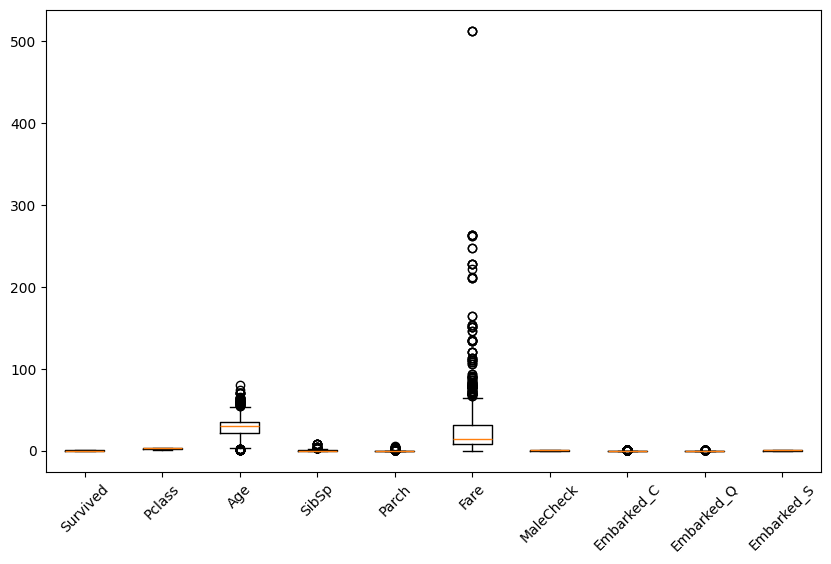

In [278]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(df_train.iloc[:,1:11])
ax.set_xticklabels(df_train.columns[1:11], rotation=45)

In [279]:

# Percebe-se que as colunas Age e Fare possuem muitos outliers, para tratar esses sera utilizado o RobustScaler.
transformer = RobustScaler().fit(df_train[['Age', 'Fare']])
df_train[['Age', 'Fare']] = transformer.transform(df_train[['Age', 'Fare']])
df_test[['Age', 'Fare']] = transformer.transform(df_test[['Age', 'Fare']])

[Text(1, 0, 'Survived'),
 Text(2, 0, 'Pclass'),
 Text(3, 0, 'Age'),
 Text(4, 0, 'SibSp'),
 Text(5, 0, 'Parch'),
 Text(6, 0, 'Fare'),
 Text(7, 0, 'MaleCheck'),
 Text(8, 0, 'Embarked_C'),
 Text(9, 0, 'Embarked_Q'),
 Text(10, 0, 'Embarked_S')]

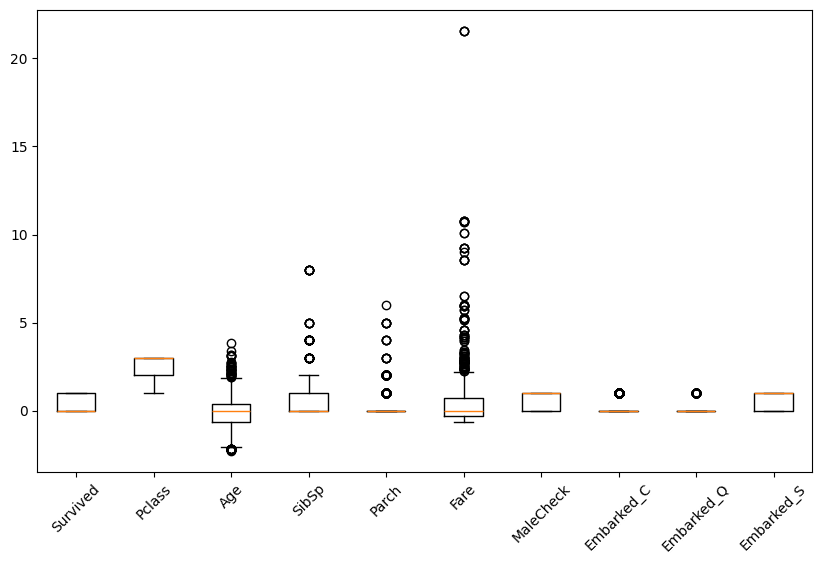

In [280]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(df_train.iloc[:,1:11])
ax.set_xticklabels(df_train.columns[1:11], rotation=45)

In [281]:
df_train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,MaleCheck,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,-0.615385,1,0,-0.312011,1,0.0,0.0,1.0
1,2,1,1,0.615385,1,0,2.461242,0,1.0,0.0,0.0
2,3,1,3,-0.307692,0,0,-0.282777,0,0.0,0.0,1.0
3,4,1,1,0.384615,1,0,1.673732,0,0.0,0.0,1.0
4,5,0,3,0.384615,0,0,-0.277363,1,0.0,0.0,1.0


In [282]:
# Criando a função de treino e previsão para evitar a repetição de código
def treinar_e_prever(df):
    X = df.drop(['PassengerId', 'Survived'], axis=1, errors='ignore')
    y = df['Survived']

    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    tree_model = DecisionTreeClassifier(random_state=42)
    tree_model.fit(X_train, y_train)
    y_pred_ac = tree_model.predict(X_val)

    knn_model = KNeighborsClassifier(n_neighbors=3)
    knn_model.fit(X_train, y_train)
    y_pred_knn = knn_model.predict(X_val)

    rl_model = LogisticRegression(random_state=42, max_iter=1000)
    rl_model.fit(X_train, y_train)
    y_pred_rl = rl_model.predict(X_val)

    as_ac = accuracy_score(y_val, y_pred_ac)
    as_knn = accuracy_score(y_val, y_pred_knn)
    as_rl = accuracy_score(y_val, y_pred_rl)

    return as_ac, as_knn, as_rl


In [283]:
# Avaliação da acurácia após o tratamento da escala
ac_tree, ac_knn, ac_rl = treinar_e_prever(df_train)


df_as['escala'] = [ac_tree, ac_knn, ac_rl]
df_as


,Modelo,Acurácia_inicial,escala
0,Árvore de Decisão,0.782123,0.776536
1,KNN,0.715084,0.837989
2,Regressão Logística,0.798883,0.810056


In [284]:
# VERIFICAÇÃO DE SOBREVIVÊNCIA PARA "SibSp" e "Parch" ANÁLISE PARA SABERMOS SE EM UMA VIAGEM COM UMA FAMILIA GRANDE OU CASAIS POSSUEM UMA CHANCE MAIOR DE SOBREVIVER.
# Sibsp: Numero de imrãos/conjugês a bordo  \  Parch: Nº de país/filhos a bordo do Titanic

In [285]:
for col in ['SibSp', 'Parch']:
    res_df = df_train.groupby(col)['Survived'].agg(total='count', tx_suvirve='mean', suvivers='sum').reset_index()
    print(f"\n=== Análise de Sobrevivência por {col} ===")
    display(res_df)


=== Análise de Sobrevivência por SibSp ===


,SibSp,total,tx_suvirve,suvivers
0,0,608,0.345395,210
1,1,209,0.535885,112
2,2,28,0.464286,13
3,3,16,0.250000,4
4,4,18,0.166667,3
5,5,5,0.000000,0
6,8,7,0.000000,0



=== Análise de Sobrevivência por Parch ===


,Parch,total,tx_suvirve,suvivers
0,0,678,0.343658,233
1,1,118,0.550847,65
2,2,80,0.500000,40
3,3,5,0.600000,3
4,4,4,0.000000,0
5,5,5,0.200000,1
6,6,1,0.000000,0


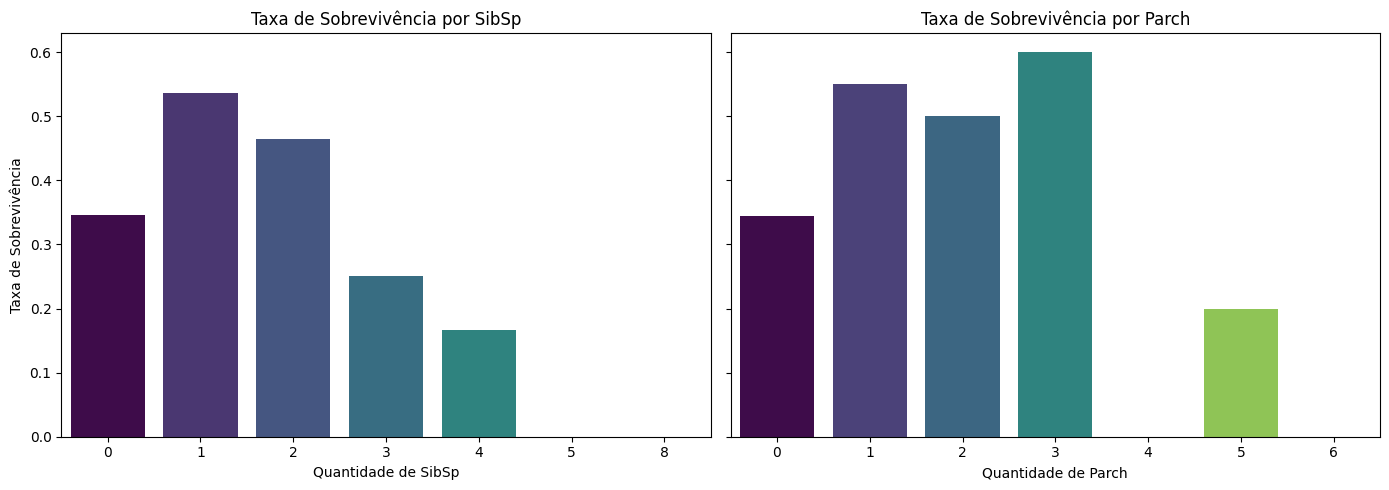

In [286]:
# Gráfico comparativo otimizado de taxas de sobrevivência para SibSp e Parch
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for i, col in enumerate(['SibSp', 'Parch']):
    sns.barplot(
        data=df_train,
        x=col,
        y='Survived',
        hue=col,
        ax=axes[i],
        errorbar=None,
        palette='viridis',
        legend=False
    )
    axes[i].set_title(f'Taxa de Sobrevivência por {col}')
    axes[i].set_ylabel('Taxa de Sobrevivência')
    axes[i].set_xlabel(f'Quantidade de {col}')

plt.tight_layout()
plt.show()

In [287]:
# Observa-se que passageiros que viajaram sozinhos obtiveram uma menor percentual de sobrevivênvia em relação aos que viajavam com alguns acompanhantes.

In [288]:
# Criando função e coluna para indentificar se o passageiro está viajando sozinho
def alone (a,b):
  if (a == 0 and b == 0):
    return 1
  else:
    return 0

df_train['Alone'] = df_train.apply(lambda x: alone(x['SibSp'], x['Parch']), axis=1)

In [289]:
df_train.groupby('Alone')[['SibSp', 'Parch']].mean()

,SibSp,Parch
Alone,,
0,1.316384,0.960452
1,0.000000,0.000000


In [290]:
df_test['Alone'] = df_test.apply(lambda x: alone(x['SibSp'], x['Parch']), axis=1)

In [291]:
# Criação de nova coluna do total de familiares
df_train['Family'] = df_train['SibSp'] + df_train['Parch']
df_test['Family'] = df_test['SibSp'] + df_test['Parch']


In [292]:
df_train['Family'] = df_train['SibSp'] + df_train['Parch']

df_family = df_train.groupby('Family')['Survived'].agg(['sum', 'count', 'mean']).reset_index()
df_family.columns = ['Family', 'survivers', 'total', 'tx_survivors']
df_family

,Family,survivers,total,tx_survivors
0,0,163,537,0.303538
1,1,89,161,0.552795
2,2,59,102,0.578431
3,3,21,29,0.724138
4,4,3,15,0.200000
5,5,3,22,0.136364
6,6,4,12,0.333333
7,7,0,6,0.000000
8,10,0,7,0.000000


In [293]:
# Avaliando acúracia com a função
ac_tree, ac_knn, ac_rl = treinar_e_prever(df_train)
df_as['people'] = [as_ac, as_knn, as_rl]
df_as

,Modelo,Acurácia_inicial,escala,people
0,Árvore de Decisão,0.782123,0.776536,0.782123
1,KNN,0.715084,0.837989,0.715084
2,Regressão Logística,0.798883,0.810056,0.798883


In [294]:
# ANALISANDO A CORRELAÇÃO ENTRE AS VARIÁVEIS

In [295]:
df_train.corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,MaleCheck,Embarked_C,Embarked_Q,Embarked_S,Alone,Family
PassengerId,1.000000,-0.005007,-0.035144,0.033019,-0.057527,-0.001652,0.012658,0.042939,-0.001205,-0.033606,0.022204,0.057462,-0.040143
Survived,-0.005007,1.000000,-0.338481,-0.070657,-0.035322,0.081629,0.257307,-0.543351,0.168240,0.003650,-0.149683,-0.203367,0.016639
Pclass,-0.035144,-0.338481,1.000000,-0.329727,0.083081,0.018443,-0.549500,0.131900,-0.243292,0.221009,0.074053,0.135207,0.065997
Age,0.033019,-0.070657,-0.329727,1.000000,-0.232440,-0.180330,0.090632,0.084660,0.032330,-0.010738,-0.021566,0.181165,-0.248954
SibSp,-0.057527,-0.035322,0.083081,-0.232440,1.000000,0.414838,0.159651,-0.114631,-0.059528,-0.026354,0.068734,-0.584471,0.890712
Parch,-0.001652,0.081629,0.018443,-0.180330,0.414838,1.000000,0.216225,-0.245489,-0.011069,-0.081228,0.060814,-0.583398,0.783111
Fare,0.012658,0.257307,-0.549500,0.090632,0.159651,0.216225,1.000000,-0.182333,0.269335,-0.117216,-0.162184,-0.271832,0.217138
MaleCheck,0.042939,-0.543351,0.131900,0.084660,-0.114631,-0.245489,-0.182333,1.000000,-0.082853,-0.074115,0.119224,0.303646,-0.200988
Embarked_C,-0.001205,0.168240,-0.243292,0.032330,-0.059528,-0.011069,0.269335,-0.082853,1.000000,-0.148258,-0.782742,-0.095298,-0.046215
Embarked_Q,-0.033606,0.003650,0.221009,-0.010738,-0.026354,-0.081228,-0.117216,-0.074115,-0.148258,1.000000,-0.499421,0.086464,-0.058592


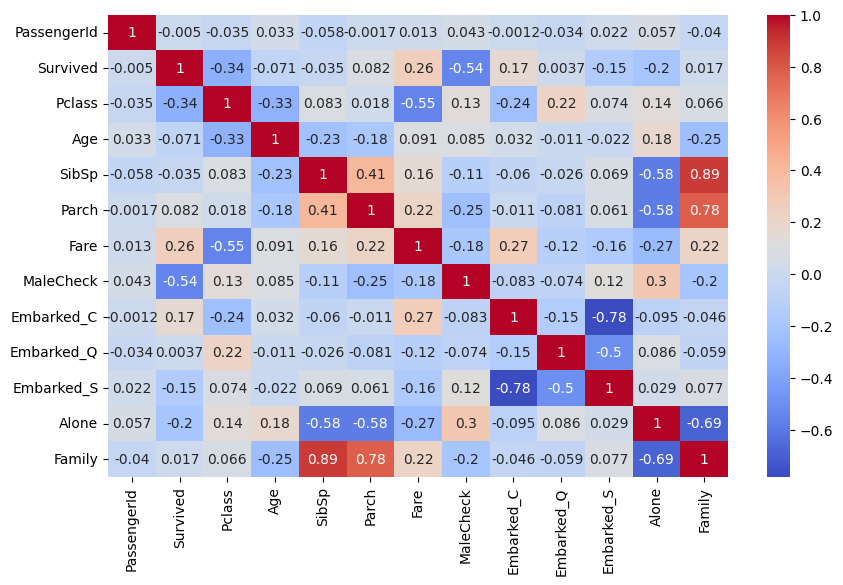

In [296]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df_train.corr(), annot=True, cmap='coolwarm', ax=ax)
plt.show()

In [297]:
# VISUALIZAÇÃO E VERIFICAÇÃO DA RELAÇÃO ENTRE 'Pclass' e 'Fare' E TAXA DE SOBREVIVÊNCIA

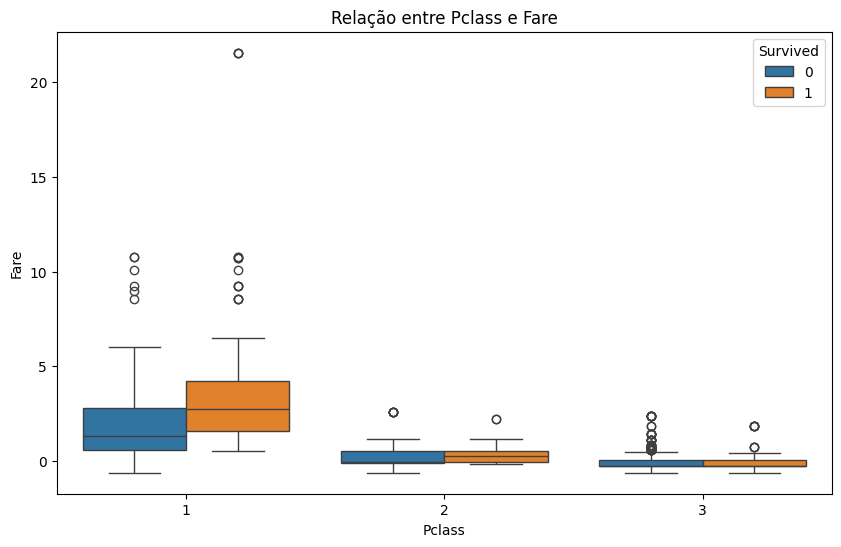

In [298]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_train, x='Pclass', y='Fare', hue='Survived')
ax.set_title('Relação entre Pclass e Fare')
plt.show()

In [299]:
display(df_train.groupby('Pclass')['Survived'].mean().sort_values(ascending=False))
display(df_train.groupby('Pclass')['Fare'].agg(['min', 'mean', 'max']))


,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


,min,mean,max
Pclass,,,
1,-0.626005,3.018696,21.562738
2,-0.626005,0.268865,2.557247
3,-0.626005,-0.033723,2.386174


In [300]:
# VERIFICAÇÃO E TRATAMENTO DA COLUNA EMBARQUE (ANALISE DA CORRELAÇÃO DA COLUNA)

In [301]:
embarked_map = {'S': 0, 'C': 1, 'Q': 2}

df_train2 = pd.read_csv('train.csv')
df_test2 = pd.read_csv('test.csv')

df_train['Embarked'] = df_train2['Embarked'].fillna('S').map(embarked_map)
df_test['Embarked'] = df_test2['Embarked'].fillna('S').map(embarked_map)

colunas_para_remover = ['Embarked_S', 'Embarked_C', 'Embarked_Q']
df_train = df_train.drop(colunas_para_remover, axis=1, errors='ignore')
df_test = df_test.drop(colunas_para_remover, axis=1, errors='ignore')

df_train.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,MaleCheck,Alone,Family,Embarked
0,1,0,3,-0.615385,1,0,-0.312011,1,0,1,0
1,2,1,1,0.615385,1,0,2.461242,0,0,1,1
2,3,1,3,-0.307692,0,0,-0.282777,0,1,0,0
3,4,1,1,0.384615,1,0,1.673732,0,0,1,0
4,5,0,3,0.384615,0,0,-0.277363,1,1,0,0


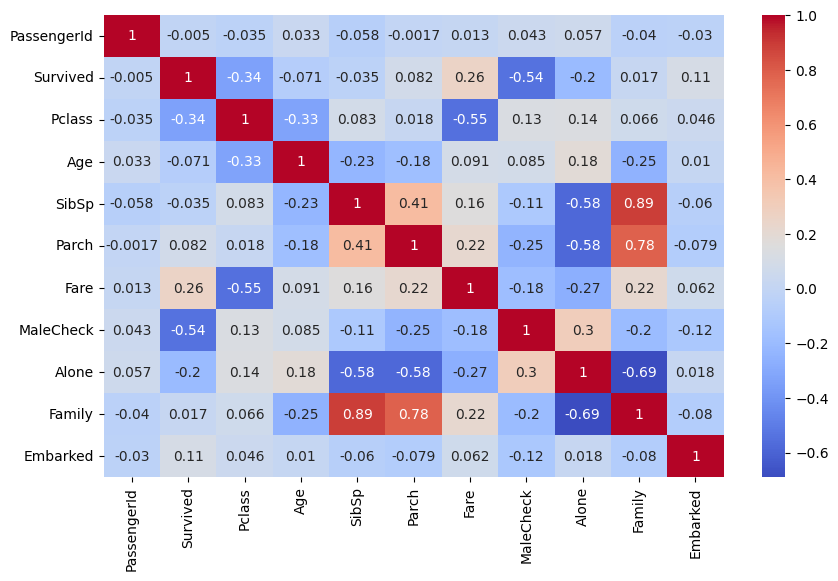

In [302]:
vfig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df_train.corr(), annot=True, cmap='coolwarm', ax=ax)
plt.show()

In [303]:
# AVALIAÇÃO DA ACURÁCIA COM INCLUSÃO DA COLUNA FAMILY E ALONE E NOVO TRATAMENTO DA COLUNA EMBARKED

In [304]:
as_ac, as_knn, as_rl = treinar_e_prever(df_train)
df_as['family'] = [as_ac, as_knn, as_rl]
df_as

,Modelo,Acurácia_inicial,escala,people,family
0,Árvore de Decisão,0.782123,0.776536,0.782123,0.776536
1,KNN,0.715084,0.837989,0.715084,0.832402
2,Regressão Logística,0.798883,0.810056,0.798883,0.798883


In [305]:
# Analisa-se que houve um regresso nas medições com os novos tratamentos

In [306]:
# UTILIZAÇÃO DOS MODELOS PARA VERIFICAR E MANTER AS COLUNAS COM MAIS IMPORTANCIA

In [307]:
X = df_train.drop(['PassengerId', 'Survived'], axis=1)
y = df_train['Survived']

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)

rl_model = LogisticRegression(random_state=42, max_iter=1000)
rl_model.fit(X, y)

columns_imp = pd.DataFrame({
    'Variável': X.columns,
    'Árvore (Ganho de Informação)': tree_model.feature_importances_,
    'Regr. Logística (Coeficientes)': rl_model.coef_[0]
})

# Ordenando pelo impacto absoluto na Regressão Logística
columns_imp['Impacto_Absoluto_RL'] = columns_imp['Regr. Logística (Coeficientes)'].abs()
columns_imp = columns_imp.sort_values(by='Impacto_Absoluto_RL', ascending=False).drop(columns=['Impacto_Absoluto_RL'])

print("=== Importância das Variáveis por Modelo ===")
display(columns_imp)

=== Importância das Variáveis por Modelo ===


,Variável,Árvore (Ganho de Informação),Regr. Logística (Coeficientes)
5,MaleCheck,0.311307,-2.535199
0,Pclass,0.108045,-1.032544
6,Alone,0.011509,-0.729300
1,Age,0.226994,-0.497247
2,SibSp,0.017571,-0.267329
7,Family,0.038069,-0.251357
8,Embarked,0.020954,0.241076
4,Fare,0.238083,0.044246
3,Parch,0.027468,0.015972


In [308]:
# Eliminado colunas menos relevantas
df_train = df_train.drop(['SibSp', 'Parch'], axis=1)
df_test = df_test.drop(['SibSp', 'Parch'], axis=1)
df_train.head(2)

,PassengerId,Survived,Pclass,Age,Fare,MaleCheck,Alone,Family,Embarked
0,1,0,3,-0.615385,-0.312011,1,0,1,0
1,2,1,1,0.615385,2.461242,0,0,1,1


In [309]:
df_train.head()
df

,PassengerId,Survived,Pclass,Age,Fare,MaleCheck,Alone,Family,Embarked
0,1,0,3,-0.615385,-0.312011,1,0,1,0
1,2,1,1,0.615385,2.461242,0,0,1,1
2,3,1,3,-0.307692,-0.282777,0,1,0,0
3,4,1,1,0.384615,1.673732,0,0,1,0
4,5,0,3,0.384615,-0.277363,1,1,0,0


In [310]:
#Avaliando a nova acurácia
as_ac, as_knn, as_rl = treinar_e_prever(df_train)

df_as['colunas'] = [as_ac, as_knn, as_rl]
df_as

,Modelo,Acurácia_inicial,escala,people,family,colunas
0,Árvore de Decisão,0.782123,0.776536,0.782123,0.776536,0.782123
1,KNN,0.715084,0.837989,0.715084,0.832402,0.810056
2,Regressão Logística,0.798883,0.810056,0.798883,0.798883,0.804469


In [315]:
# Utilizando Knn
X_atual = df_train.drop(['PassengerId', 'Survived'], axis=1, errors='ignore')
y_atual = df_train['Survived']

knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_atual, y_atual)

X_test = df_test[X_atual.columns]

y_pred_test = knn_model.predict(X_test)

df_test['Survived'] = y_pred_test
df_test[['PassengerId', 'Survived']].head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1


In [316]:
base_envio = df_test[['PassengerId', 'Survived']]
base_envio.to_csv('resultado3.csv', index=False)

In [318]:
# Utilizando modelo Rl.
rl_model_final = LogisticRegression(random_state=42, max_iter=1000)
rl_model_final.fit(X_atual, y_atual)

X_test_rl = df_test[X_atual.columns]

y_pred_rl_test = rl_model_final.predict(X_test_rl)

base_envio_rl = pd.DataFrame({
    'PassengerId': df_test['PassengerId'],
    'Survived': y_pred_rl_test
})

base_envio_rl.to_csv('resultado_rl.csv', index=False)

### Conclusão e Resultados das Otimizações

Nesta etapa, realizamos um pipeline completo de otimização dos nossos modelos preditivos para o desafio do Titanic:

1. **Tratamento de Escala (`RobustScaler`):**
   - Ajustamos as variáveis `Age` e `Fare` para mitigar o impacto de outliers, o que elevou a acurácia do modelo **KNN de 71.5% para 83.7%**.

2. **Engenharia de Features:**
   - Criamos as variáveis `Alone` (indicando se o passageiro viajava sozinho) e `Family` (tamanho da família) para capturar o impacto das relações familiares na taxa de sobrevivência.

3. **Seleção de Atributos:**
   - Analisamos a importância de cada variável utilizando a árvore de decisão e os coeficientes da regressão logística, optando por remover as colunas redundantes `SibSp` e `Parch` para evitar sobreajuste.

4. **Geração das Submissões:**
   - **`resultado2.csv`**: Exportamos as previsões do modelo de **Regressão Logística** onde apresentou o melhor resultado da submissão.
   - **`resultado3.csv`**: Exportamos as previsões do modelo **KNN** (com acurácia de validação de ~81.0%).
   - **`resultado_rl.csv`**: Exportamos as previsões do modelo de **Regressão Logística** (com acurácia de validação de ~80.4%). Apesar de ser menor na acurácia de validação, na submissão apresentou um resultado melhor do que o KNN.

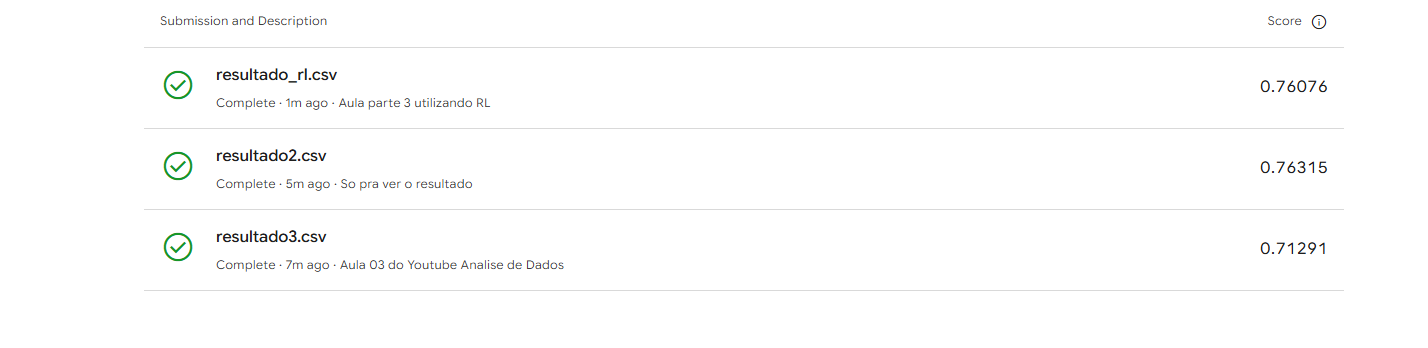